In [1]:
import os
import glob
import pandas as pd
import numpy as np
import cv2
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from tqdm.notebook import tqdm_notebook
import re
tqdm_notebook.pandas()
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras import callbacks
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.efficientnet import EfficientNetB7
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2
from tensorflow.keras.applications.densenet import DenseNet121
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import f1_score , recall_score, accuracy_score, precision_score, confusion_matrix
from keras.utils import np_utils
from sklearn.model_selection import train_test_split
from sklearn import metrics
import itertools
import pickle
from joblib import dump, load

In [2]:
df_train_img = pd.read_csv('C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\save fichier rakuten\\df_train_final.csv')

df_train_img= df_train_img.drop("Unnamed: 0", axis=1)
df_train_img.head(1)

,designation,description,productid,imageid,nom_img,Texte,prdtypecode,Catégories,cat_code
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,image_1263597046_product_3804725264,olivia personalisiertes notizbuch seiten punkt...,10,Livres occasions,0


In [3]:
# Supprimer la colonne prdtypecode
df_train_img.drop(columns=['prdtypecode'], inplace=True)

# Renommer la colonne cat_code en prdtypecode
df_train_img.rename(columns={'cat_code': 'prdtypecode'}, inplace=True)


In [4]:
# L'emplacement que vous souhaitez ajouter
emplacement = 'C:\\Users\\yahya\\OneDrive\Documents\\Rakuten\\images\\images\\image_resized\\'

# Fonction pour ajouter l'emplacement au nom de l'image
def ajouter_emplacement(nom_img):
    return emplacement + nom_img + ".jpg"

# Appliquer la fonction à la colonne 'nom_img'
df_train_img['nom_img'] = df_train_img['nom_img'].apply(ajouter_emplacement)

df_train_img.head()

,designation,description,productid,imageid,nom_img,Texte,Catégories,prdtypecode
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,C:\Users\yahya\OneDrive\Documents\Rakuten\imag...,olivia personalisiertes notizbuch seiten punkt...,Livres occasions,0
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,NaN,436067568,1008141237,C:\Users\yahya\OneDrive\Documents\Rakuten\imag...,journal arts art marche salon art asiatique pa...,"Journaux, revues d'occasion",18
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo...,PILOT STYLE Touch Pen de marque Speedlink est ...,201115110,938777978,C:\Users\yahya\OneDrive\Documents\Rakuten\imag...,grand stylet ergonomique bleu gamepad nintendo...,accessories gaming,2
3,Peluche Donald - Europe - Disneyland 2000 (Mar...,NaN,50418756,457047496,C:\Users\yahya\OneDrive\Documents\Rakuten\imag...,peluche donald europe disneyland marionnette d...,Jouets petite enfance,7
4,La Guerre Des Tuques,Luc a des id&eacute;es de grandeur. Il veut or...,278535884,1077757786,C:\Users\yahya\OneDrive\Documents\Rakuten\imag...,guerre tuques luc grandeur veut organiser jeu ...,Livres neufs,25


In [5]:
df_train_img["prdtypecode"] = df_train_img["prdtypecode"].astype('str')

In [6]:
df_train_img.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84916 entries, 0 to 84915
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   designation  84916 non-null  object
 1   description  55116 non-null  object
 2   productid    84916 non-null  int64 
 3   imageid      84916 non-null  int64 
 4   nom_img      84916 non-null  object
 5   Texte        84906 non-null  object
 6   Catégories   84916 non-null  object
 7   prdtypecode  84916 non-null  object
dtypes: int64(2), object(6)
memory usage: 5.2+ MB


In [7]:
df_train_img.shape

(84916, 8)

#  MobileNetV2

In [37]:
img_rows = 250
img_cols = 250
batch_size = 64
epochs = 13
emplacement = 'C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\images\\images\\image_resized'

#Split Train Set

In [10]:
# Split Train set 
X_train, X_test = train_test_split(df_train_img, train_size=0.8)

In [11]:
display(X_train.shape)
display(X_test.shape)

(67932, 8)

(16984, 8)

#Data Generator

In [38]:
img_rows = 250
img_cols = 250
batch_size = 64
epochs = 13

In [39]:
%%time
#Générateur de données
train_datagen = ImageDataGenerator(rescale = 1/255, 
                             validation_split = 0.2)

valid_datagen = ImageDataGenerator(rescale=1./255)

CPU times: total: 0 ns
Wall time: 0 ns


In [40]:
%%time

#Itérateur 
train_generator = train_datagen.flow_from_dataframe(dataframe = X_train,
                                              directory = 'C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\images\\images\\image_resized',
                                              as_ext = True,
                                              x_col = 'nom_img',
                                              y_col = 'prdtypecode',                                             
                                              class_mode = 'sparse',                                             
                                              target_size = (img_rows , img_cols),                                            
                                              batch_size = batch_size,                                             
                                              shuffle = True 
                                             )




# validation_split the validation batches ca be retrieved by specifying the subset as validation.
valid_generator = valid_datagen.flow_from_dataframe(dataframe = X_test, 
                                              directory = 'C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\images\\images\\image_resized',
                                              as_ext = True,
                                              x_col = 'nom_img',
                                              y_col = 'prdtypecode',                                             
                                              class_mode = 'sparse',                                        
                                              target_size = (img_rows , img_cols),                                        
                                              batch_size = batch_size, 
                                              shuffle = False
                                             )

Found 67932 validated image filenames belonging to 27 classes.
Found 16984 validated image filenames belonging to 27 classes.
CPU times: total: 4.8 s
Wall time: 6.16 s


#Xception implémentation

In [41]:
%%time
# Chargement du modèle MobileNetV2
#mobileNetV2 = MobileNetV2(weights='imagenet', include_top = False, input_shape=(img_rows,img_rows,3))
mobileNetV2 = MobileNetV2(weights=None , include_top = False, input_shape=(img_rows,img_rows,3))
# Bloquage du blackbone
for layer in mobileNetV2.layers:
    layer.trainable = False

CPU times: total: 1.09 s
Wall time: 1.35 s


#Mobilenet Implementation - with fine tuning

In [42]:
# Débloquer la moitié du base_model 
for layer in mobileNetV2.layers[-60:]:
    layer.trainable = True

In [43]:
model_mobileNetV2 = Sequential()
model_mobileNetV2.add(mobileNetV2)
# Ajout des couche de classification
model_mobileNetV2.add(GlobalAveragePooling2D()) 
model.add(Dense(units = 1024,activation='relu'))

model_mobileNetV2.add(Dropout(rate = 0.2))
model_mobileNetV2.add(Dense(units = 512, activation='relu'))

model_mobileNetV2.add(Dropout(rate = 0.2))
model_mobileNetV2.add(Dense(units = 27, activation='softmax'))
model_mobileNetV2.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenetv2_1.00_250 (Func  (None, 8, 8, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling2d_2  (None, 1280)              0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dropout_4 (Dropout)         (None, 1280)              0         
                                                                 
 dense_7 (Dense)             (None, 512)               655872    
                                                                 
 dropout_5 (Dropout)         (None, 512)               0         
                                                                 
 dense_8 (Dense)             (None, 27)               

In [44]:
print("Base_Model length: ", len(mobileNetV2.layers))
print(" Added model length: ", len( model_mobileNetV2.layers))

print('Last the last ten layers base model - Xception: \n ')  
for layer in mobileNetV2.layers[-10:]:
    print("                 ", layer.name, "  " , layer.trainable)
    
print('\n Layers of built model: \n')  

for layer in model_mobileNetV2.layers:
    print("                 ", layer.name, "  " , layer.trainable)

Base_Model length:  154
 Added model length:  6
Last the last ten layers base model - Xception: 
 
                  block_16_expand_BN    True
                  block_16_expand_relu    True
                  block_16_depthwise    True
                  block_16_depthwise_BN    True
                  block_16_depthwise_relu    True
                  block_16_project    True
                  block_16_project_BN    True
                  Conv_1    True
                  Conv_1_bn    True
                  out_relu    True

 Layers of built model: 

                  mobilenetv2_1.00_250    True
                  global_average_pooling2d_2    True
                  dropout_4    True
                  dense_7    True
                  dropout_5    True
                  dense_8    True


#Compilation

In [45]:
%%time
# Compilation
model_mobileNetV2.compile(loss='sparse_categorical_crossentropy',  # fonction de perte
              optimizer= Adam(learning_rate= 0.0004) ,   #default lr = 0.001 # algorithme de descente de gradient
              metrics=['accuracy'])                    # métrique d'évaluation

CPU times: total: 31.2 ms
Wall time: 15.4 ms


#Callback

In [46]:
# For saving Callbacks and history results
nbr_Epochs = epochs

In [47]:
%%time

file_name = 'checkpoint_mobileNetV2_' + '_Shape_250x250_' + str(nbr_Epochs)+ 'Epochs.h5'

#Sauvegarder les meilleurs poids du modèle au cours de l'entraînement :
checkpoint = ModelCheckpoint(filepath ='C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\DL\\Tensorflow\\MobileNet' + file_name , 
                             monitor ='val_accuracy',
                             verbose = 1,
                             save_best_only = True, # (pour que le meilleur modèle ne soit pas écrasé)
                             save_weights_only = False,
                             mode ='max', #(permet de préciser si la métrique doit croître ou décroitre : ici on choisit 'min'
                                           #car la métrique est une perte à minimiser)
                             save_freq='epoch')
#Arrêter l'entraînement si le modèle n'évolue plus (très pratique pour ne pas gérer le
#nombre d'epoch) :
# A modifier pour avoir des 
early = EarlyStopping(monitor='val_loss',
                      min_delta = 0,
                      patience = 6, #(nombre d'epochs à attendre avant d'arrêter l'entraînement
                      restore_best_weights = True,
                      verbose = 1,
                      mode = 'min')


CPU times: total: 0 ns
Wall time: 0 ns


#Fit - train_generator

In [48]:
step_size_Train = train_generator.n//train_generator.batch_size
step_size_Valid = valid_generator.n//valid_generator.batch_size
print('step_size_Train : ' , step_size_Train)
print('step_size_Valid  : ' , step_size_Valid)

step_size_Train :  1061
step_size_Valid  :  265


In [49]:
%%time
# Fit Train generator
history = model_mobileNetV2.fit(train_generator,                    
                    epochs = epochs,                   
                    steps_per_epoch = step_size_Train,
                    validation_data = valid_generator,
                    validation_steps = step_size_Valid
                    )

Epoch 1/13


1061/1061 [==============================] - 1413s 1s/step - loss: 2.5106 - accuracy: 0.2816 - val_loss: 3.6710 - val_accuracy: 0.0562
Epoch 2/13
1061/1061 [==============================] - 1486s 1s/step - loss: 2.2064 - accuracy: 0.3628 - val_loss: 4.4254 - val_accuracy: 0.0562
Epoch 3/13
1061/1061 [==============================] - 1242s 1s/step - loss: 2.0625 - accuracy: 0.4012 - val_loss: 4.2609 - val_accuracy: 0.0562
Epoch 4/13
1061/1061 [==============================] - 1160s 1s/step - loss: 1.9566 - accuracy: 0.4294 - val_loss: 4.2053 - val_accuracy: 0.0568
Epoch 5/13
1061/1061 [==============================] - 1139s 1s/step - loss: 1.8669 - accuracy: 0.4512 - val_loss: 3.5639 - val_accuracy: 0.1160
Epoch 6/13
1061/1061 [==============================] - 1121s 1s/step - loss: 1.7831 - accuracy: 0.4743 - val_loss: 4.8772 - val_accuracy: 0.0167
Epoch 7/13
1061/1061 [==============================] - 1114s 1s/step - loss: 1.6988 - accuracy: 0.4956 - val_loss: 3.6974

In [50]:
# Save History results
filename = 'history_mobileNetV2_all_train_' + '_Shape_250x250_'+ str(nbr_Epochs) +'Epochs'

In [54]:
#convert the history.history dict to a pandas DataFrame:     
hist_df = pd.DataFrame(history.history) 

# history to json:  
hist_json_file = 'C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\DL\\Tensorflow\\MobileNet' + filename + '.json'
with open(hist_json_file, mode='w') as f:
    hist_df.to_json(f)

# history to csv: 
hist_csv_file = 'C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\DL\\Tensorflow\\MobileNet' + filename +'.csv'
with open(hist_csv_file, mode='w') as f:
    hist_df.to_csv(f)

# history to pickle file
hist_df.to_pickle('C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\DL\\Tensorflow\\MobileNet'+ filename +'.pkl')

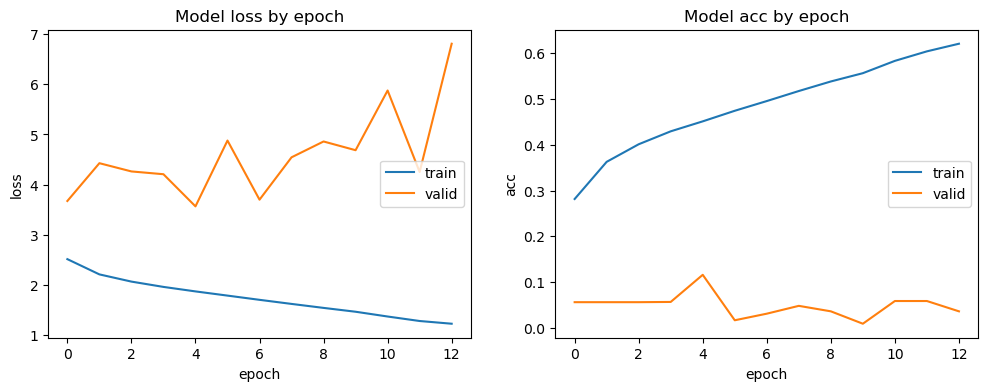

In [55]:
plt.figure(figsize=(12,4))
plt.subplot(121)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss by epoch')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='right')

plt.subplot(122)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model acc by epoch')
plt.ylabel('acc')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='right')
plt.show()

#Prediction test_generator

In [58]:
%%time
#Prediction - Valid set
y_pred_proba = model_mobileNetV2.predict(valid_generator)

# l'argmax pour obtenir les classes prédites
y_pred_class = np.argmax(y_pred_proba,axis = 1).astype(int)

# To get classes from test generator
y_true = valid_generator.classes

266/266 [==============================] - 97s 360ms/step
CPU times: total: 1min 15s
Wall time: 1min 37s


#Evaluation - test_generator

In [59]:
%%time
#Get the accuracy score
valid_score = model_mobileNetV2.evaluate(valid_generator)
print("[INFO] Model metrics names:", model_mobileNetV2.metrics_names)
print("[INFO] Accuracy: {:.2f}%".format(valid_score[1] * 100)) 
print("[INFO] Loss: ",valid_score[0])

266/266 [==============================] - 127s 477ms/step - loss: 6.8089 - accuracy: 0.0363
[INFO] Model metrics names: ['loss', 'accuracy']
[INFO] Accuracy: 3.63%
[INFO] Loss:  6.808850288391113
CPU times: total: 1min 41s
Wall time: 2min 7s


In [60]:
f1_macro = f1_score(y_true, y_pred_class, average='macro')
print("[INFO] f1 score macro average: ",f1_macro)

f1_micro = f1_score(y_true, y_pred_class, average='micro')
print("[INFO] f1 score micro average: ",f1_micro)

f1_weighted = f1_score(y_true, y_pred_class, average='weighted')
print("[INFO] f1 score weighted average: ",f1_weighted)

[INFO] f1 score macro average:  0.002592592592592593
[INFO] f1 score micro average:  0.03626943005181347
[INFO] f1 score weighted average:  0.0025388601036269434


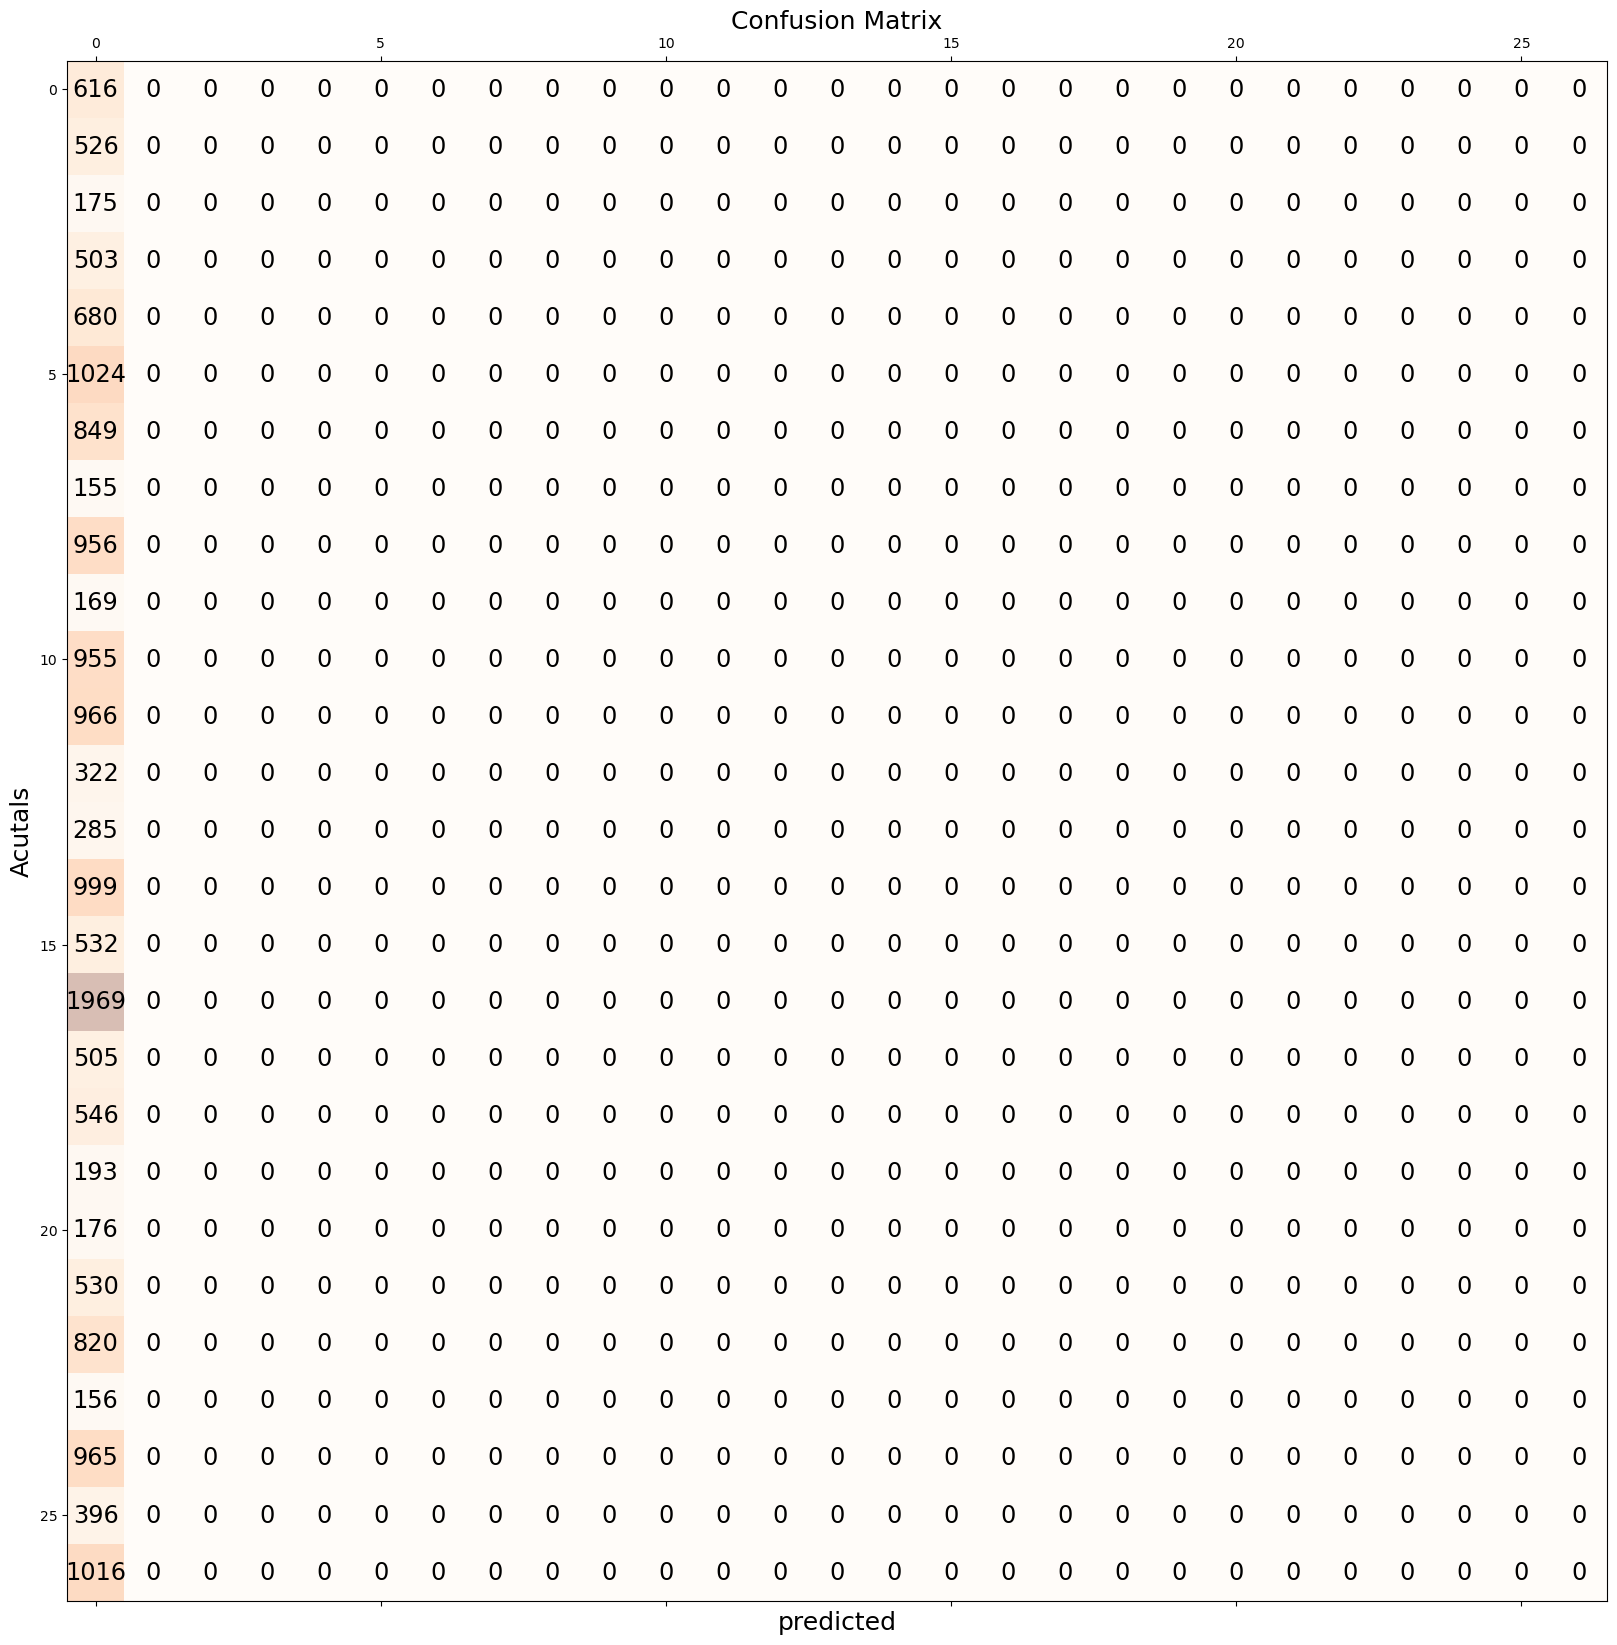

In [61]:
#Confusion matrix
matrix = confusion_matrix(y_true, y_pred_class)
fig , ax = plt.subplots(figsize = (24,20))
ax.matshow(matrix, cmap = plt.cm.Oranges , alpha = 0.3)
for i in range(matrix.shape[0]):
    for j in range (matrix.shape[1]):
        ax.text (x = j , y= i, s= matrix[i,j], va = 'center', ha = 'center', size = 'xx-large')
        
plt.xlabel('predicted', fontsize = 18)
plt.ylabel('Acutals', fontsize = 18)
plt.title('Confusion Matrix', fontsize = 18)
plt.show()
#print(matrix)

In [62]:
print(metrics.classification_report(y_true, y_pred_class))

              precision    recall  f1-score   support

           0       0.04      1.00      0.07       616
           1       0.00      0.00      0.00       526
           2       0.00      0.00      0.00       175
           3       0.00      0.00      0.00       503
           4       0.00      0.00      0.00       680
           5       0.00      0.00      0.00      1024
           6       0.00      0.00      0.00       849
           7       0.00      0.00      0.00       155
           8       0.00      0.00      0.00       956
           9       0.00      0.00      0.00       169
          10       0.00      0.00      0.00       955
          11       0.00      0.00      0.00       966
          12       0.00      0.00      0.00       322
          13       0.00      0.00      0.00       285
          14       0.00      0.00      0.00       999
          15       0.00      0.00      0.00       532
          16       0.00      0.00      0.00      1969
          17       0.00    

C:\Users\yahya\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\yahya\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\yahya\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [63]:
#Enregistrement d'un modèle Keras :
model_Densenet.save('C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\DL\\Tensorflow\\MobileNet\\MobileNet_train_img_all_10032024_13_epoch.h5py")


SyntaxError: unterminated string literal (detected at line 2) (3742878970.py, line 2)

In [ ]:
#Rechargement du modèle :
lenet = load_model('C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\DL\\Tensorflow\\MobileNet\\MobileNet_train_img_all_10032024_13_epoch.h5py")